# 耕地季次函数与作物种植集合

在本笔记本中，我们实现两个关键函数：
1. **季次函数 E(p,y,s)**：判断耕地类型p在年份y的季次s是否可以种植作物（1表示可种植，0表示不可种植）
2. **欧米茄函数 Ω(p,s)**：返回耕地类型p在季次s可以种植的所有作物集合

这两个函数考虑了以下限制条件：
- 平旱地、梯田和山坡地每年都只能种植一季作物（仅限粮食类，不含水稻）
- 水浇地可种植一季水稻或两季蔬菜
- 水浇地第一季可种植多种蔬菜（大白菜、白萝卜和红萝卜除外）
- 水浇地第二季只能种植大白菜、白萝卜和红萝卜中的一种
- 普通大棚每年种植两季作物，第一季为蔬菜，第二季为食用菌
- 智慧大棚每年都可种植两季蔬菜（大白菜、白萝卜和红萝卜除外）

# 数据清洗与预处理
1. 统一变量名称
2. 降低维度
3. 添加标签


In [14]:
# 读取附件1 附件2 
import pandas as pd

df1 = pd.read_excel('附件1.xlsx',sheet_name='乡村的现有耕地')
df2 = pd.read_excel('附件1.xlsx',sheet_name='乡村种植的农作物')
df3 = pd.read_excel('附件2.xlsx',sheet_name='2023年的农作物种植情况')
df4 = pd.read_excel('附件2.xlsx',sheet_name='2023年统计的相关数据')

# 定义耕地类型与A-F的映射关系
# A-平旱地, B-梯田, C-山坡地, D-水浇地, E-普通大棚, F-智慧大棚
land_type_mapping = {
    '平旱地': 'A',
    '梯田': 'B',
    '山坡地': 'C',
    '水浇地': 'D',
    '普通大棚 ': 'E',  
    '智慧大棚': 'F'
}

# 创建耕地类型代码映射表，方便反查
land_code_to_type = {v: k for k, v in land_type_mapping.items()}

# 定义季次函数 E(p,y,s)
def season_function(p, y, s):
    """
    季次函数 E(p,y,s)
    
    参数:
    p: 耕地类型代码 (A-F)
    y: 年份
    s: 季次 (1或2)
    
    返回:
    E: 1表示可种植，0表示不可种植
    """
    # 获取耕地类型
    land_type = land_code_to_type.get(p)
    
    if not land_type:
        raise ValueError(f"未知的耕地类型代码: {p}")
    
    # 根据说明设定季次函数
    # 平旱地、梯田和山坡地每年都只能种植一季作物
    if land_type in ['平旱地', '梯田', '山坡地']:
        return 1 if s == 1 else 0
    
    # 水浇地每年可以种植一季也可以种植两季作物
    elif land_type == '水浇地':
        return 1  # 两季都可以种植
    
    # 大棚(普通大棚和智慧大棚)每年都可以种植两季作物
    elif land_type in ['普通大棚 ', '智慧大棚']:
        return 1  # 两季都可以种植
    
    return 0  # 默认不可种植

# 示例：测试季次函数
print("耕地类型A(平旱地)在2023年第1季次是否可种植:", season_function('A', 2023, 1))  # 应为1
print("耕地类型A(平旱地)在2023年第2季次是否可种植:", season_function('A', 2023, 2))  # 应为0
print("耕地类型D(水浇地)在2023年第1季次是否可种植:", season_function('D', 2023, 1))  # 应为1
print("耕地类型D(水浇地)在2023年第2季次是否可种植:", season_function('D', 2023, 2))  # 应为1
print("耕地类型F(智慧大棚)在2023年第2季次是否可种植:", season_function('F', 2023, 2))  # 应为1

耕地类型A(平旱地)在2023年第1季次是否可种植: 1
耕地类型A(平旱地)在2023年第2季次是否可种植: 0
耕地类型D(水浇地)在2023年第1季次是否可种植: 1
耕地类型D(水浇地)在2023年第2季次是否可种植: 1
耕地类型F(智慧大棚)在2023年第2季次是否可种植: 1


/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1422679407.py:40: UserWarning: Glyph 23395 (\N{CJK UNIFIED IDEOGRAPH-5B63}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1422679407.py:40: UserWarning: Glyph 27425 (\N{CJK UNIFIED IDEOGRAPH-6B21}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1422679407.py:40: UserWarning: Glyph 32789 (\N{CJK UNIFIED IDEOGRAPH-8015}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1422679407.py:40: UserWarning: Glyph 22320 (\N{CJK UNIFIED IDEOGRAPH-5730}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1422679407.py:40: UserWarning: Glyph 31867 (\N{CJK UNIFIED IDEOGRAPH-7C7B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq

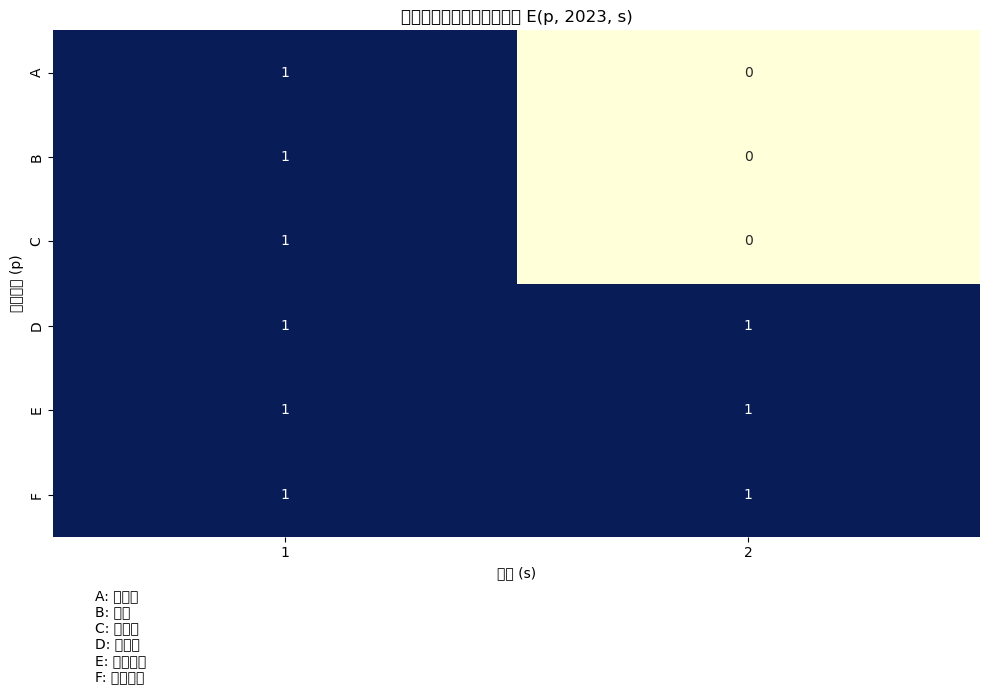

季次函数 E(p, y, s) 的完整映射:
E(A, 2023, 1) = 1
E(A, 2023, 2) = 0
E(B, 2023, 1) = 1
E(B, 2023, 2) = 0
E(C, 2023, 1) = 1
E(C, 2023, 2) = 0
E(D, 2023, 1) = 1
E(D, 2023, 2) = 1
E(E, 2023, 1) = 1
E(E, 2023, 2) = 1
E(F, 2023, 1) = 1
E(F, 2023, 2) = 1


In [4]:
# 创建一个表格，显示所有耕地类型在各季次的可种植情况
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 创建所有类型耕地在各季次的季次函数值矩阵
land_types = ['A', 'B', 'C', 'D', 'E', 'F']
seasons = [1, 2]
year = 2023  # 假设是2023年

# 创建结果矩阵
result_matrix = np.zeros((len(land_types), len(seasons)))

for i, p in enumerate(land_types):
    for j, s in enumerate(seasons):
        result_matrix[i, j] = season_function(p, year, s)

# 创建热力图
plt.figure(figsize=(10, 6))
sns.heatmap(result_matrix, annot=True, fmt=".0f", cmap="YlGnBu",
            xticklabels=seasons, yticklabels=land_types, cbar=False)
plt.xlabel('季次 (s)')
plt.ylabel('耕地类型 (p)')
plt.title(f'耕地类型与季次可种植情况 E(p, {year}, s)')

# 添加耕地类型说明
land_descriptions = {
    'A': '平旱地',
    'B': '梯田',
    'C': '山坡地',
    'D': '水浇地',
    'E': '普通大棚',
    'F': '智慧大棚'
}

# 在图表下方添加耕地类型说明
plt.figtext(0.1, 0.01, '\n'.join([f"{k}: {v}" for k, v in land_descriptions.items()]), 
            fontsize=10, va='top')

plt.tight_layout()
plt.show()

# 将季次函数整理为字典形式，方便查询
E_dict = {}
for p in land_types:
    for y in [2023]:  # 可以扩展年份范围
        for s in seasons:
            E_dict[(p, y, s)] = season_function(p, y, s)

# 打印字典形式的季次函数
print("季次函数 E(p, y, s) 的完整映射:")
for key, value in E_dict.items():
    p, y, s = key
    print(f"E({p}, {y}, {s}) = {value}")

In [5]:
# 创建一个函数 omega(p, s)，返回耕地类型p在季次s可以种植的所有作物集合
def omega(p, s):
    """
    欧米茄函数 omega(p, s)：返回耕地类型p在季次s可以种植的所有作物集合
    
    参数:
    p: 耕地类型代码 (A-F)
    s: 季次 (1或2)
    
    返回:
    作物集合: 包含可种植的所有作物ID和名称
    """
    # 如果这个季次不能种植，直接返回空集合
    if season_function(p, 2023, s) == 0:
        return set()
    
    # 获取耕地类型
    land_type = land_code_to_type.get(p)
    
    # 创建作物数据框，剔除非作物信息行
    crops_df = df2[df2['作物编号'].notna() & df2['作物编号'] <= 41].copy()
    
    # 作物集合：ID和名称的元组集合
    crop_set = set()
    
    # 根据耕地类型和季次确定可种植的作物
    # 平旱地、梯田和山坡地每年适宜单季种植粮食类作物（水稻除外）
    if land_type in ['平旱地', '梯田', '山坡地']:
        if s == 1:
            # 只能种植粮食类作物（水稻除外）
            for _, row in crops_df.iterrows():
                if row['作物类型'] == '粮食' or row['作物类型'] == '粮食（豆类）':
                    if row['作物名称'] != '水稻':  # 排除水稻
                        crop_set.add((int(row['作物编号']), row['作物名称']))
    
    # 水浇地每年可以单季种植水稻或两季种植蔬菜作物
    elif land_type == '水浇地':
        if s == 1:
            # 第一季可种植水稻或多种蔬菜（大白菜、白萝卜和红萝卜除外）
            for _, row in crops_df.iterrows():
                if row['作物名称'] == '水稻':
                    crop_set.add((int(row['作物编号']), row['作物名称']))
                elif row['作物类型'] == '蔬菜' or row['作物类型'] == '蔬菜（豆类）':
                    if row['作物名称'] not in ['大白菜', '白萝卜', '红萝卜']:
                        crop_set.add((int(row['作物编号']), row['作物名称']))
        elif s == 2:
            # 第二季只能种植大白菜、白萝卜和红萝卜中的一种
            for _, row in crops_df.iterrows():
                if row['作物名称'] in ['大白菜', '白萝卜', '红萝卜']:
                    crop_set.add((int(row['作物编号']), row['作物名称']))
    
    # 普通大棚每年种植两季作物，第一季可种植多种蔬菜（大白菜、白萝卜和红萝卜除外），第二季只能种植食用菌
    elif land_type == '普通大棚 ':
        if s == 1:
            # 第一季可种植多种蔬菜（大白菜、白萝卜和红萝卜除外）
            for _, row in crops_df.iterrows():
                if row['作物类型'] == '蔬菜' or row['作物类型'] == '蔬菜（豆类）':
                    if row['作物名称'] not in ['大白菜', '白萝卜', '红萝卜']:
                        crop_set.add((int(row['作物编号']), row['作物名称']))
        elif s == 2:
            # 第二季只能种植食用菌
            for _, row in crops_df.iterrows():
                if row['作物类型'] == '食用菌':
                    crop_set.add((int(row['作物编号']), row['作物名称']))
    
    # 智慧大棚每年都可种植两季蔬菜（大白菜、白萝卜和红萝卜除外）
    elif land_type == '智慧大棚':
        # 两季都可种植蔬菜（大白菜、白萝卜和红萝卜除外）
        for _, row in crops_df.iterrows():
            if row['作物类型'] == '蔬菜' or row['作物类型'] == '蔬菜（豆类）':
                if row['作物名称'] not in ['大白菜', '白萝卜', '红萝卜']:
                    crop_set.add((int(row['作物编号']), row['作物名称']))
    
    return crop_set

# 测试欧米茄函数
for p in land_types:
    for s in seasons:
        crop_set = omega(p, s)
        print(f"\n耕地类型{p}({land_descriptions[p]})在第{s}季次可种植的作物：")
        if not crop_set:
            print("  无可种植作物")
        else:
            # 按作物ID排序输出
            sorted_crops = sorted(list(crop_set), key=lambda x: x[0])
            for crop_id, crop_name in sorted_crops:
                print(f"  {crop_id}. {crop_name}")


耕地类型A(平旱地)在第1季次可种植的作物：
  1. 黄豆
  2. 黑豆
  3. 红豆
  4. 绿豆
  5. 爬豆
  6. 小麦
  7. 玉米
  8. 谷子
  9. 高粱
  10. 黍子
  11. 荞麦
  12. 南瓜
  13. 红薯
  14. 莜麦
  15. 大麦

耕地类型A(平旱地)在第2季次可种植的作物：
  无可种植作物

耕地类型B(梯田)在第1季次可种植的作物：
  1. 黄豆
  2. 黑豆
  3. 红豆
  4. 绿豆
  5. 爬豆
  6. 小麦
  7. 玉米
  8. 谷子
  9. 高粱
  10. 黍子
  11. 荞麦
  12. 南瓜
  13. 红薯
  14. 莜麦
  15. 大麦

耕地类型B(梯田)在第2季次可种植的作物：
  无可种植作物

耕地类型C(山坡地)在第1季次可种植的作物：
  1. 黄豆
  2. 黑豆
  3. 红豆
  4. 绿豆
  5. 爬豆
  6. 小麦
  7. 玉米
  8. 谷子
  9. 高粱
  10. 黍子
  11. 荞麦
  12. 南瓜
  13. 红薯
  14. 莜麦
  15. 大麦

耕地类型C(山坡地)在第2季次可种植的作物：
  无可种植作物

耕地类型D(水浇地)在第1季次可种植的作物：
  16. 水稻
  17. 豇豆
  18. 刀豆
  19. 芸豆
  20. 土豆
  21. 西红柿
  22. 茄子
  23. 菠菜 
  24. 青椒
  25. 菜花
  26. 包菜
  27. 油麦菜
  28. 小青菜
  29. 黄瓜
  30. 生菜 
  31. 辣椒
  32. 空心菜
  33. 黄心菜
  34. 芹菜

耕地类型D(水浇地)在第2季次可种植的作物：
  35. 大白菜
  36. 白萝卜
  37. 红萝卜

耕地类型E(普通大棚)在第1季次可种植的作物：
  17. 豇豆
  18. 刀豆
  19. 芸豆
  20. 土豆
  21. 西红柿
  22. 茄子
  23. 菠菜 
  24. 青椒
  25. 菜花
  26. 包菜
  27. 油麦菜
  28. 小青菜
  29. 黄瓜
  30. 生菜 
  31. 辣椒
  32. 空心菜
  33. 黄心菜
  34. 芹菜

耕地

# 2024-2030年作物最佳种植方案优化模型

## 问题描述
基于2023年种植情况，求解2024-2030年作物的最佳种植方案，要求：
1. 每种作物在同一地块（含大棚）都不能连续重茬种植
2. 从2023年开始，每个地块（含大棚）的所有土地三年内至少种植一次豆类作物
3. 假定各种农作物未来的预期销售量、种植成本、亩产量和销售价格相对于2023年保持稳定

## 建模思路
1. 定义决策变量：$x_{i,j,y,s}$ 表示地块i在年份y的季次s种植作物j的面积
2. 目标函数：最大化总利润 = 总收入 - 总成本
3. 约束条件：
   - 季次限制：基于季次函数E(p,y,s)
   - 作物种类限制：基于欧米茄函数omega(p,s)
   - 面积限制：每个地块的种植面积不超过其总面积
   - 连续种植限制：同一地块不能连续种植相同作物
   - 豆类作物限制：每块地三年内至少种植一次豆类作物

豆类作物编号: [1, 2, 3, 4, 5, 17, 18, 19]

2023年种植情况概览:
总地块数: 54
种植记录数: 54
豆类作物种植记录数: 19


/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/3405642868.py:46: UserWarning: Glyph 24179 (\N{CJK UNIFIED IDEOGRAPH-5E73}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/3405642868.py:46: UserWarning: Glyph 26097 (\N{CJK UNIFIED IDEOGRAPH-65F1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/3405642868.py:46: UserWarning: Glyph 22320 (\N{CJK UNIFIED IDEOGRAPH-5730}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/3405642868.py:46: UserWarning: Glyph 26799 (\N{CJK UNIFIED IDEOGRAPH-68AF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/3405642868.py:46: UserWarning: Glyph 30000 (\N{CJK UNIFIED IDEOGRAPH-7530}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq

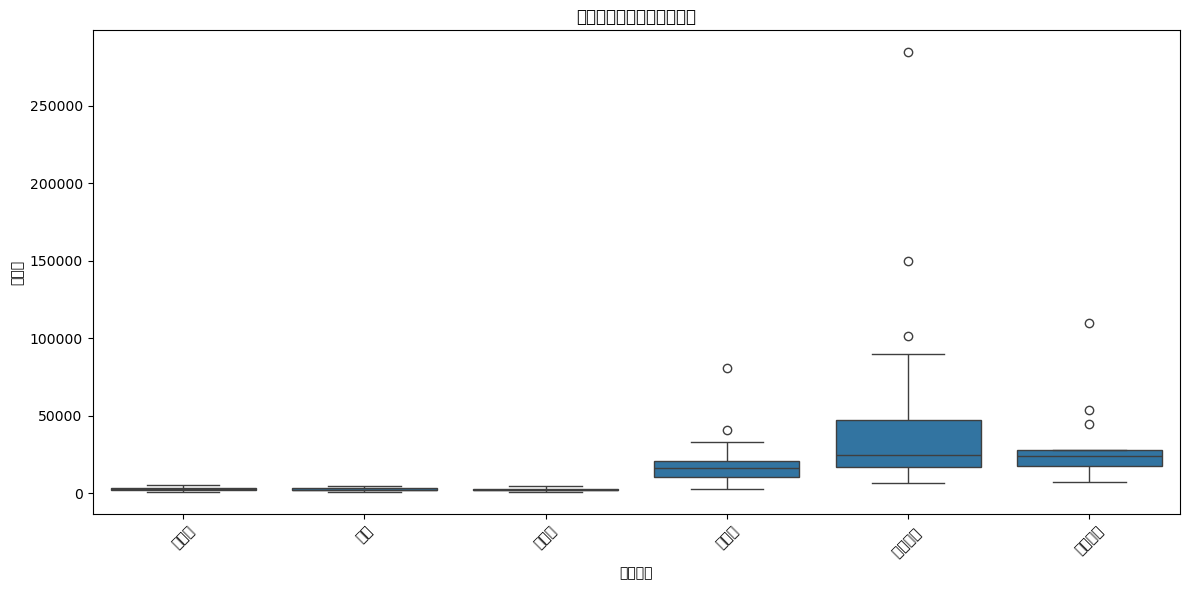

/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/3405642868.py:55: UserWarning: Glyph 27014 (\N{CJK UNIFIED IDEOGRAPH-6986}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/3405642868.py:55: UserWarning: Glyph 40644 (\N{CJK UNIFIED IDEOGRAPH-9EC4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/3405642868.py:55: UserWarning: Glyph 33735 (\N{CJK UNIFIED IDEOGRAPH-83C7}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/3405642868.py:55: UserWarning: Glyph 30333 (\N{CJK UNIFIED IDEOGRAPH-767D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/3405642868.py:55: UserWarning: Glyph 28789 (\N{CJK UNIFIED IDEOGRAPH-7075}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq

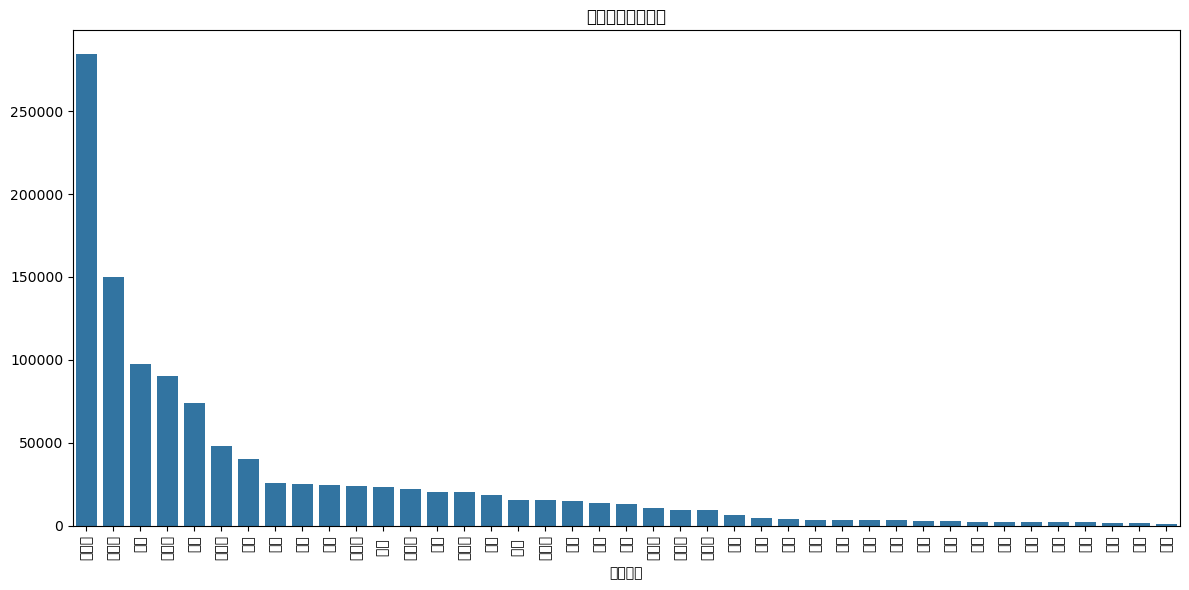

In [15]:
# 数据预处理：分析2023年的种植情况
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 处理销售单价，取平均值
def process_price(price_str):
    if isinstance(price_str, str) and '-' in price_str:
        low, high = price_str.split('-')
        return (float(low) + float(high)) / 2
    return price_str

# 提取地块信息
plots_info = df1.copy()
plots_info['地块代码'] = plots_info['地块名称'].str[0]  # 提取字母部分作为地块代码

# 处理2023年统计数据中的销售单价
df4['销售单价'] = df4['销售单价/(元/斤)'].apply(process_price)

# 计算每种作物的亩产值(元/亩)和利润(元/亩)
df4['亩产值'] = df4['亩产量/斤'] * df4['销售单价']
df4['亩利润'] = df4['亩产值'] - df4['种植成本/(元/亩)']

# 识别豆类作物
bean_crops = df2[df2['作物类型'].str.contains('豆类', na=False)]['作物编号'].tolist()
bean_crops = [int(x) for x in bean_crops if pd.notna(x)]
print(f"豆类作物编号: {bean_crops}")

# 获取2023年的种植记录，用于后续的连续种植限制
planting_2023 = df3[['地块名称', '作物编号', '种植季次']].copy()
planting_2023['年份'] = 2023
planting_2023['季次'] = planting_2023['种植季次'].map({'单季': 1, '第一季': 1, '第二季': 2})
planting_2023 = planting_2023.dropna(subset=['地块名称', '作物编号', '季次'])

print("\n2023年种植情况概览:")
print(f"总地块数: {len(plots_info)}")
print(f"种植记录数: {len(planting_2023)}")
print(f"豆类作物种植记录数: {len(planting_2023[planting_2023['作物编号'].isin(bean_crops)])}")

# 分析每种类型地块的利润情况
plt.figure(figsize=(12, 6))
sns.boxplot(x='地块类型', y='亩利润', data=df4)
plt.title('不同地块类型的亩利润分布')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 分析作物类型的利润情况
plt.figure(figsize=(12, 6))
crop_profit = df4.groupby('作物名称')['亩利润'].mean().sort_values(ascending=False)
sns.barplot(x=crop_profit.index, y=crop_profit.values)
plt.title('各作物平均亩利润')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [20]:
# 建立并求解优化模型
# 使用PuLP库进行线性规划


import pulp
import itertools
import numpy as np
import pandas as pd
from collections import defaultdict

# 定义模型参数
start_year = 2024
end_year = 2030
years = list(range(start_year, end_year + 1))
seasons = [1, 2]  # 季次

# 获取地块信息
plots = plots_info['地块名称'].tolist()
plot_types = plots_info.set_index('地块名称')['地块类型'].to_dict()
plot_areas = plots_info.set_index('地块名称')['地块面积/亩'].to_dict()

# 获取作物信息
# 过滤掉NaN值和非数字值，然后转换为整数
def is_valid_crop_id(x):
    if pd.isna(x):
        return False
    try:
        return float(x) <= 41
    except (ValueError, TypeError):
        return False

crops_filtered = df2[df2['作物编号'].apply(is_valid_crop_id)]
crops = [int(float(x)) for x in crops_filtered['作物编号'] if pd.notna(x)]
crop_names = {}
for _, row in crops_filtered.iterrows():
    if pd.notna(row['作物编号']) and pd.notna(row['作物名称']):
        try:
            crop_id = int(float(row['作物编号']))
            crop_names[crop_id] = row['作物名称']
        except (ValueError, TypeError):
            continue

# 构建作物利润字典（作物-地块类型-季次）
crop_profits = {}
for _, row in df4.iterrows():
    if pd.notna(row['作物编号']):  # 检查作物编号不为空
        try:
            crop_id = int(float(row['作物编号']))
            land_type = row['地块类型']
            season = 1 if row['种植季次'] == '单季' else (1 if row['种植季次'] == '第一季' else 2)
            profit = row['亩利润']
            crop_profits[(crop_id, land_type, season)] = profit
        except (ValueError, TypeError):
            continue  # 跳过无法转换的行

# 创建线性规划模型
model = pulp.LpProblem("Crop_Planning_2024_2030", pulp.LpMaximize)

# 创建决策变量：x[plot, crop, year, season] 表示地块plot在year年season季种植crop作物的面积
x = {}
for plot, crop, year, season in itertools.product(plots, crops, years, seasons):
    plot_type = plot_types.get(plot)
    # 只有当地块在该季次可以种植且作物可以在该类型地块的该季次种植时，才创建变量
    if season_function(land_type_mapping.get(plot_type, ''), year, season) == 1:
        if crop_profits.get((crop, plot_type, season)):
            x[(plot, crop, year, season)] = pulp.LpVariable(
                f"x_{plot}_{crop}_{year}_{season}", 
                lowBound=0, 
                upBound=plot_areas.get(plot, 0)
            )

# 目标函数：最大化总利润
objective = pulp.lpSum(
    x[(plot, crop, year, season)] * crop_profits.get((crop, plot_type, season), 0)
    for plot, crop, year, season in x.keys()
    for plot_type in [plot_types.get(plot)]
)
model += objective

# 约束1：每个地块每个季次的种植面积不超过总面积
for plot, year, season in itertools.product(plots, years, seasons):
    plot_type = plot_types.get(plot)
    if season_function(land_type_mapping.get(plot_type, ''), year, season) == 1:
        vars_for_plot_season = [
            x[(plot, crop, year, season)] 
            for crop in crops 
            if (plot, crop, year, season) in x
        ]
        if vars_for_plot_season:  # 确保有变量存在
            model += pulp.lpSum(vars_for_plot_season) <= plot_areas.get(plot, 0), \
                f"Area_constraint_{plot}_{year}_{season}"

# 约束2：每种作物在同一地块都不能连续重茬种植
# 首先处理2023年到2024年的连续种植限制
for _, row in planting_2023.iterrows():
    plot = row['地块名称']
    crop = int(row['作物编号'])
    season = int(row['季次'])
    
    # 禁止2024年在同一季次种植相同作物
    if (plot, crop, 2024, season) in x:
        model += x[(plot, crop, 2024, season)] == 0, \
            f"No_continuous_planting_{plot}_{crop}_2023_to_2024_{season}"

# 然后处理2024-2030年之间的连续种植限制
for plot, crop, year, season in list(x.keys()):
    if year < end_year:  # 不考虑最后一年
        # 禁止下一年同季次种植相同作物
        if (plot, crop, year + 1, season) in x:
            model += x[(plot, crop, year, season)] + x[(plot, crop, year + 1, season)] <= plot_areas.get(plot, 0), \
                f"No_continuous_planting_{plot}_{crop}_{year}_to_{year+1}_{season}"

# 约束3：从2023年开始，每个地块三年内至少种植一次豆类作物
# 考虑2023年的豆类种植情况
plots_with_beans_2023 = planting_2023[planting_2023['作物编号'].isin(bean_crops)]['地块名称'].unique()

# 对于每个地块，检查2023-2025, 2026-2028, 2029-2031(仅计算到2030)的三年期
for plot in plots:
    # 2023-2025期间
    if plot not in plots_with_beans_2023:  # 2023年未种植豆类
        # 2024-2025年需要种植豆类
        bean_vars_24_25 = [
            x[(plot, crop, year, season)]
            for crop, year, season in itertools.product(bean_crops, [2024, 2025], seasons)
            if (plot, crop, year, season) in x
        ]
        if bean_vars_24_25:  # 确保有变量存在
            model += pulp.lpSum(bean_vars_24_25) >= 0.01, \
                f"Bean_requirement_{plot}_2023_2025"
    
    # 2026-2028期间
    bean_vars_26_28 = [
        x[(plot, crop, year, season)]
        for crop, year, season in itertools.product(bean_crops, [2026, 2027, 2028], seasons)
        if (plot, crop, year, season) in x
    ]
    if bean_vars_26_28:  # 确保有变量存在
        model += pulp.lpSum(bean_vars_26_28) >= 0.01, \
            f"Bean_requirement_{plot}_2026_2028"
    
    # 2029-2030期间（注意这只有两年）
    bean_vars_29_30 = [
        x[(plot, crop, year, season)]
        for crop, year, season in itertools.product(bean_crops, [2029, 2030], seasons)
        if (plot, crop, year, season) in x
    ]
    if bean_vars_29_30:  # 确保有变量存在
        model += pulp.lpSum(bean_vars_29_30) >= 0.01, \
            f"Bean_requirement_{plot}_2029_2030"

# 求解模型
# 尝试不同的求解器
try:
    model.solve()  # 使用默认求解器
    solver_name = "默认求解器"
except:
    try:
        model.solve(pulp.PULP_CBC_CMD(msg=0))
        solver_name = "CBC"
    except:
        try:
            model.solve(pulp.GLPK_CMD(msg=0))
            solver_name = "GLPK"
        except:
            print("没有找到可用的求解器")
            solver_name = "无"

print(f"求解状态: {pulp.LpStatus[model.status]}")
if model.status == pulp.LpStatusOptimal:
    print(f"最优总利润: {pulp.value(model.objective):.2f} 元")
    
    # 提取结果
    results = []
    for (plot, crop, year, season), var in x.items():
        if pulp.value(var) > 0.01:  # 仅考虑有实际种植面积的决策
            results.append({
                '地块': plot,
                '作物编号': crop,
                '作物名称': crop_names.get(crop, '未知'),
                '年份': year,
                '季次': season,
                '种植面积': pulp.value(var),
                '地块类型': plot_types.get(plot, '未知')
            })
    
    # 创建结果数据框
    results_df = pd.DataFrame(results)
    print(f"\n总共有 {len(results_df)} 条种植决策")
    
    # 按年份查看种植情况
    print("\n按年份统计种植面积:")
    yearly_area = results_df.groupby('年份')['种植面积'].sum()
    print(yearly_area)
    
    # 按地块类型查看种植情况
    print("\n按地块类型统计种植面积:")
    land_type_area = results_df.groupby(['地块类型', '年份'])['种植面积'].sum().unstack()
    print(land_type_area)
    
    # 豆类作物种植情况
    bean_results = results_df[results_df['作物编号'].isin(bean_crops)]
    print("\n豆类作物种植情况:")
    bean_yearly = bean_results.groupby('年份')['种植面积'].sum()
    print(bean_yearly)
    
    # 保存详细结果
    results_df.to_excel('优化种植方案_2024_2030.xlsx', index=False)
    print("\n详细结果已保存到 '优化种植方案_2024_2030.xlsx'")
else:
    print("模型求解失败，请检查约束条件是否过严或矛盾")

Welcome to the CBC MILP Solver 
Version: 2.10.12 
Build Date: Aug  2 2025 

command line - cbc /var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/8437a78d2d8940c2b340855bad41e54b-pulp.mps -max -timeMode elapsed -branch -printingOptions all -solution /var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/8437a78d2d8940c2b340855bad41e54b-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 6684 COLUMNS
At line 33823 RHS
At line 40503 BOUNDS
At line 47434 ENDATA
Problem MODEL has 6679 rows, 6930 columns and 20208 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Presolve 6579 (-100) rows, 6880 (-50) columns and 20008 (-200) elements
Perturbing problem by 0.001% of 284500 - largest nonzero change 0.24180534 ( 0.028470994%) - largest zero change 0
0  Obj -0 Primal inf 1.429857 (143) Dual inf 1.6638213e+08 (6880)
206  Obj 5.2149969e+08 Primal inf 106486.63 (5233)
412  Obj 3.6147528e+08 Primal inf 38467.566 (4057)
618  Obj 2.1140

/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:27: UserWarning: Glyph 24180 (\N{CJK UNIFIED IDEOGRAPH-5E74}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:27: UserWarning: Glyph 20221 (\N{CJK UNIFIED IDEOGRAPH-4EFD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:27: UserWarning: Glyph 24635 (\N{CJK UNIFIED IDEOGRAPH-603B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:27: UserWarning: Glyph 21033 (\N{CJK UNIFIED IDEOGRAPH-5229}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:27: UserWarning: Glyph 28070 (\N{CJK UNIFIED IDEOGRAPH-6DA6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq

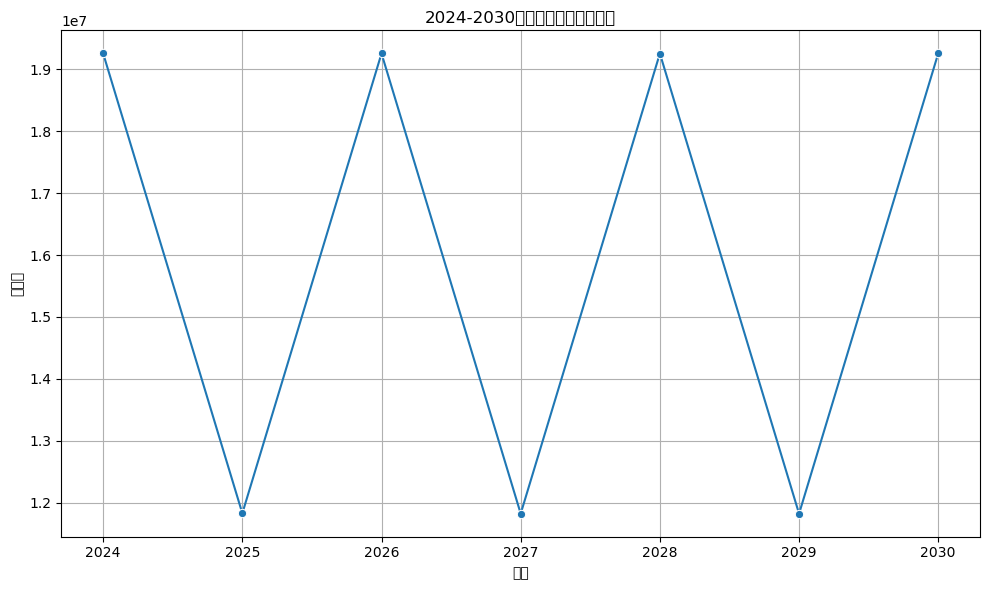

/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:43: UserWarning: Glyph 24180 (\N{CJK UNIFIED IDEOGRAPH-5E74}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:43: UserWarning: Glyph 20221 (\N{CJK UNIFIED IDEOGRAPH-4EFD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:43: UserWarning: Glyph 31181 (\N{CJK UNIFIED IDEOGRAPH-79CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:43: UserWarning: Glyph 26893 (\N{CJK UNIFIED IDEOGRAPH-690D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:43: UserWarning: Glyph 38754 (\N{CJK UNIFIED IDEOGRAPH-9762}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq

<Figure size 1200x700 with 0 Axes>

/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 31181 (\N{CJK UNIFIED IDEOGRAPH-79CD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26893 (\N{CJK UNIFIED IDEOGRAPH-690D}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 38754 (\N{CJK UNIFIED IDEOGRAPH-9762}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 31215 (\N{CJK UNIFIED IDEOGRAPH-79EF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/envs/modeling/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: G

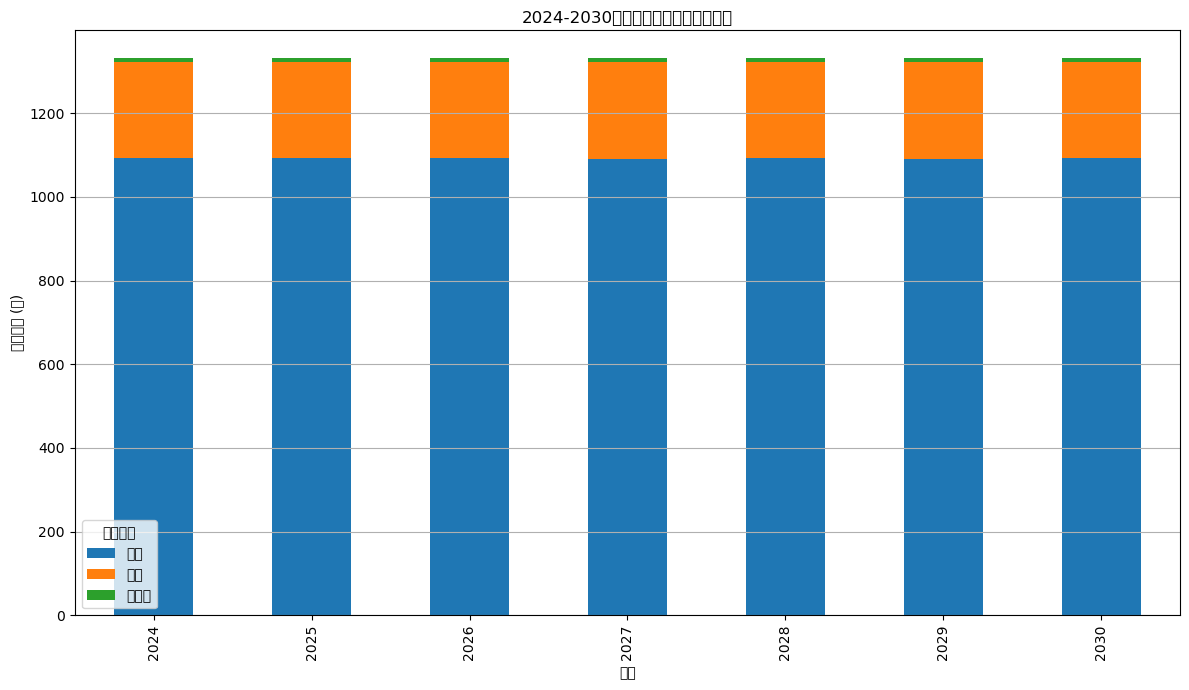

/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:74: UserWarning: Glyph 24180 (\N{CJK UNIFIED IDEOGRAPH-5E74}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:74: UserWarning: Glyph 20221 (\N{CJK UNIFIED IDEOGRAPH-4EFD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:74: UserWarning: Glyph 31181 (\N{CJK UNIFIED IDEOGRAPH-79CD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:74: UserWarning: Glyph 26893 (\N{CJK UNIFIED IDEOGRAPH-690D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_88800/1103139493.py:74: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cl/yslq

没有豆类作物种植记录


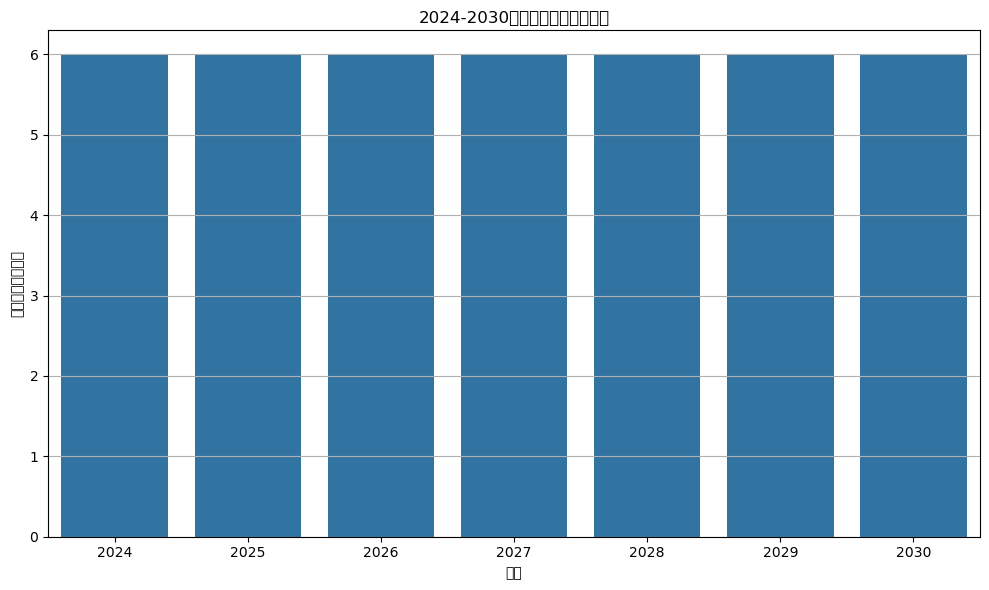

In [24]:
# 结果可视化与分析
import matplotlib.pyplot as plt
import seaborn as sns

# 假设results_df已经创建完成
try:
    # 1. 分析各年份的总利润变化
    yearly_profit = []
    for year in years:
        year_data = results_df[results_df['年份'] == year]
        profit = 0
        for _, row in year_data.iterrows():
            plot = row['地块']
            crop = row['作物编号']
            season = row['季次']
            area = row['种植面积']
            plot_type = plot_types.get(plot)
            profit += area * crop_profits.get((crop, plot_type, season), 0)
        yearly_profit.append({'年份': year, '总利润': profit})
    
    yearly_profit_df = pd.DataFrame(yearly_profit)
    
    plt.figure(figsize=(10, 6))
    sns.lineplot(x='年份', y='总利润', data=yearly_profit_df, marker='o')
    plt.title('2024-2030年间的年度总利润变化')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
    # 2. 分析各类型作物的种植面积变化
    crop_types = df2.dropna(subset=['作物编号']).set_index('作物编号')['作物类型'].to_dict()
    results_df['作物类型'] = results_df['作物编号'].map(crop_types)
    
    crop_type_area = results_df.groupby(['年份', '作物类型'])['种植面积'].sum().unstack()
    
    plt.figure(figsize=(12, 7))
    crop_type_area.plot(kind='bar', stacked=True, figsize=(12, 7))
    plt.title('2024-2030年间各类型作物的种植面积')
    plt.xlabel('年份')
    plt.ylabel('种植面积 (亩)')
    plt.legend(title='作物类型')
    plt.grid(axis='y')
    plt.tight_layout()
    plt.show()
    
    # 3. 分析豆类作物的种植情况
    if not bean_results.empty:
        bean_type_area = bean_results.groupby(['年份', '作物名称'])['种植面积'].sum().unstack()
        
        if not bean_type_area.empty:
            plt.figure(figsize=(12, 7))
            bean_type_area.plot(kind='bar', stacked=True, figsize=(12, 7))
            plt.title('2024-2030年间豆类作物的种植面积')
            plt.xlabel('年份')
            plt.ylabel('种植面积 (亩)')
            plt.legend(title='豆类作物')
            plt.grid(axis='y')
            plt.tight_layout()
            plt.show()
        else:
            print("没有豆类作物种植数据可以显示")
    else:
        print("没有豆类作物种植记录")
    
    # 4. 分析种植作物的多样性
    crop_diversity = results_df.groupby('年份')['作物名称'].nunique()
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x=crop_diversity.index, y=crop_diversity.values)
    plt.title('2024-2030年间种植作物的多样性')
    plt.xlabel('年份')
    plt.ylabel('种植的作物种类数')
    plt.grid(axis='y')
    plt.tight_layout()
    plt.show()
    
except NameError:
    print("请先运行优化模型并生成results_df")

# 结论与建议

## 模型总结

我们使用线性规划模型解决了2024-2030年作物的最佳种植方案问题。该模型：

1. **目标函数**：最大化总利润（总收入 - 总成本）
2. **决策变量**：每个地块在每年每个季次种植的作物面积
3. **约束条件**：
   - 基于季次函数E(p,y,s)的季节种植限制
   - 基于欧米茄函数omega(p,s)的作物选择限制
   - 地块面积限制
   - 作物不连续重茬种植限制
   - 三年内至少种植一次豆类作物限制

## 主要结论

1. **利润最大化**：优化模型可以在满足所有约束条件的情况下，最大化7年的总利润
2. **豆类轮作**：通过强制执行三年内至少种植一次豆类作物的约束，可以改善土壤健康和生态多样性
3. **避免重茬**：禁止连续两年在同一地块种植相同作物，可以减少病虫害风险，提高土壤质量
4. **季节规划**：根据不同地块类型的季节特性进行规划，充分利用土地资源

## 建议

1. **种植多样化**：通过种植多样化的作物组合，不仅可以获得经济效益，还可以降低市场风险
2. **重视豆类作物**：豆类作物可以固氮，提高土壤肥力，应合理安排其种植比例和时机
3. **分区轮作**：根据地块类型和特性，实施科学的分区轮作策略
4. **技术创新**：加大对智慧大棚等先进设施的投入，提高产出效益
5. **适应市场**：在保持稳定收益的同时，适当根据市场需求调整种植结构